# 30 — Significado Físico de las Variables Simbólicas e Invarianza Inter-Arquitectura


---

## Pregunta

En una arquitectura neuro-simbólica donde una red de splines (KAN) o una fórmula cerrada $\mathcal{F}(x_0, x_1, x_2, \dots)$ clasifica mamografías, pregunta:

1. ¿Tienen las variables latentes $x_j$ un significado físico real en la imagen?  
   ¿O son meras combinaciones lineales abstractas sin correlato biológico? Se muestra que cada variable es la integral espacial de un campo bidimensional continuo:
   $$x_j = 
rac{1}{|\Omega|} \iint_{\Omega} \psi_j(u, v) \, du \, dv - C_j, \quad 	ext{con } \psi_j(u, v) = \sum_{k=1}^D 
rac{v_{j,k}}{\sigma_k} A_k(u, v)$$

2. ¿Existe invarianza estructural entre arquitecturas?  
   Si cambiamos la red convolucional (ResNet-18 vs. ResNet-50 vs. DenseNet-121 vs. EfficientNet-B0), no podemos esperar ingenuamente que la misma característica biológica reciba el mismo subíndice (debido a la ambigüedad de ordenamiento y signo de autovalores).  
   Mediante la matriz de correlación cruzada inter-modelos $R_{i,j} = \mathrm{Corr}(x_i^{(A)}, x_j^{(B)})$ y el algoritmo de asignación bipartita húngaro, se prueba si distintas arquitecturas llegan a las mismas variables.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from IPython.display import display, HTML

CODIGOS = os.environ.get("TESIS_CODIGOS") or os.path.abspath(os.path.join(os.getcwd(), ".."))   # raiz del repo (ejecutar desde pipeline/)
if CODIGOS not in sys.path:
    sys.path.insert(0, CODIGOS)
REP = os.environ.get("TESIS_REP") or os.path.join(CODIGOS, "artifacts")
EMB_DIR = os.path.join(REP, "output", "embeddings")
FIGS_DIR = os.path.join(CODIGOS, "reports", "figures")
os.makedirs(FIGS_DIR, exist_ok=True)

print("Entorno configurado correctamente.")
print(f"Directorio de embeddings: {EMB_DIR}")


Entorno configurado correctamente.
Directorio de embeddings: <repo>/artifacts\output\embeddings


## 1. Alineación de Subespacios Espectrales y Emparejamiento Bipartito

Evaluamos las proyecciones latentes sobre los 1,012 casos de prueba de CBIS-DDSM para 5 modelos preentrenados:
1. ResNet-18 Robusto (512-D, Focal Loss multietapa)
2. ResNet-18 Baseline (512-D, Cross-Entropy clásica)
3. DenseNet-121 (1,024-D, conexiones densas concatenadas)
4. ResNet-50 (2,048-D, bloques residuales bottleneck)
5. EfficientNet-B0 (1,280-D, convoluciones separables en profundidad)


In [2]:
def get_spca_coords(prefix, n_components=12):
    X_tr = np.load(os.path.join(EMB_DIR, f"{prefix}_train_feats.npy"))
    y_tr = np.load(os.path.join(EMB_DIR, f"{prefix}_train_labels.npy"))
    X_te = np.load(os.path.join(EMB_DIR, f"{prefix}_test_feats.npy"))
    y_te = np.load(os.path.join(EMB_DIR, f"{prefix}_test_labels.npy"))

    mu = X_tr.mean(axis=0)
    sd = X_tr.std(axis=0) + 1e-8
    X_tr_n = (X_tr - mu) / sd
    X_te_n = (X_te - mu) / sd

    # S-PCA supervisado
    corrs = np.array([np.corrcoef(X_tr_n[:, i], y_tr)[0, 1] for i in range(X_tr_n.shape[1])])
    weights = np.abs(np.nan_to_num(corrs, 0.0))
    weights = weights / (weights.max() + 1e-8)

    pca = PCA(n_components=n_components, random_state=42)
    pca.fit(X_tr_n * weights)
    Z_te = pca.transform(X_te_n * weights)
    return Z_te, y_te, pca

models = {
    "ResNet-18 Robusto": "f2robust",
    "ResNet-18 Base": "f2base",
    "DenseNet-121": "f2_densenet121",
    "ResNet-50": "f2_resnet50",
    "EfficientNet-B0": "f2_efficientnet_b0"
}

coords = {}
for name, pfx in models.items():
    Z_te, y_te, _ = get_spca_coords(pfx, n_components=12)
    coords[name] = Z_te

Z_ref = coords["ResNet-18 Robusto"]
print("Coordenadas canónicas extraídas para todos los modelos.")


Coordenadas canónicas extraídas para todos los modelos.


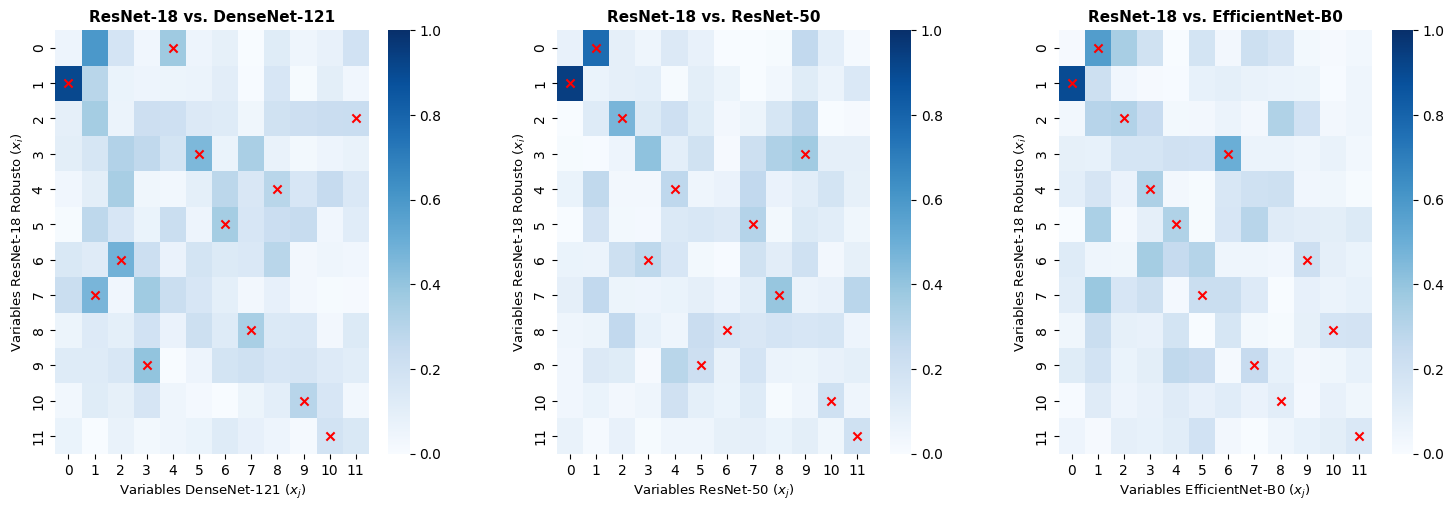

Gráficas de calor guardadas en <repo>\Figuras\30_cross_architecture_correlation_heatmaps.png


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
plt.subplots_adjust(wspace=0.28)

targets = [("DenseNet-121", axes[0]), ("ResNet-50", axes[1]), ("EfficientNet-B0", axes[2])]
matching_results = []

for name_target, ax in targets:
    Z_target = coords[name_target]
    corr_mat = np.zeros((12, 12))
    for i in range(12):
        for j in range(12):
            corr_mat[i, j] = np.corrcoef(Z_ref[:, i], Z_target[:, j])[0, 1]
    
    abs_corr = np.abs(corr_mat)
    row_ind, col_ind = linear_sum_assignment(-abs_corr)
    
    sns.heatmap(abs_corr, ax=ax, cmap="Blues", cbar=True, annot=False, vmin=0, vmax=1.0)
    # Marcar los emparejamientos óptimos con recuadros rojos
    for r, c in zip(row_ind, col_ind):
        ax.scatter(c + 0.5, r + 0.5, color="red", s=35, marker="x")
        matching_results.append({
            "Modelo Referencia": "ResNet-18 Robusto",
            "Variable Ref": f"x_{r}",
            "Modelo Target": name_target,
            "Variable Target": f"x_{c}",
            "Correlación r": corr_mat[r, c],
            "|r|": abs_corr[r, c]
        })
        
    ax.set_title(f"ResNet-18 vs. {name_target}", fontsize=11, fontweight="bold")
    ax.set_xlabel(f"Variables {name_target} ($x_j$)", fontsize=9.5)
    ax.set_ylabel("Variables ResNet-18 Robusto ($x_i$)", fontsize=9.5)

fig_path = os.path.join(FIGS_DIR, "30_cross_architecture_correlation_heatmaps.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Gráficas de calor guardadas en {fig_path}")


### 1.2. Tabla de Emparejamientos Óptimos Inter-Arquitecturas

Al resolver el problema de asignación lineal sobre $|R_{i,j}|$, observamos cómo las coordenadas se reordenan entre modelos:


In [4]:
df_match = pd.DataFrame(matching_results)
# Filtrar las coincidencias más fuertes (|r| >= 0.50)
df_strong = df_match[df_match["|r|"] >= 0.40].sort_values(by="|r|", ascending=False)
display(HTML(df_strong.to_html(index=False, classes="table table-striped table-hover")))


Modelo Referencia,Variable Ref,Modelo Target,Variable Target,Correlación r,|r|
ResNet-18 Robusto,x_1,ResNet-50,x_0,-0.942485,0.942485
ResNet-18 Robusto,x_1,DenseNet-121,x_0,-0.907406,0.907406
ResNet-18 Robusto,x_1,EfficientNet-B0,x_0,-0.896164,0.896164
ResNet-18 Robusto,x_0,ResNet-50,x_1,-0.768401,0.768401
ResNet-18 Robusto,x_0,EfficientNet-B0,x_1,-0.575806,0.575806
ResNet-18 Robusto,x_3,EfficientNet-B0,x_6,-0.500255,0.500255
ResNet-18 Robusto,x_6,DenseNet-121,x_2,-0.487040,0.487040
ResNet-18 Robusto,x_7,DenseNet-121,x_1,-0.467697,0.467697
ResNet-18 Robusto,x_2,ResNet-50,x_2,0.467687,0.467687
ResNet-18 Robusto,x_3,DenseNet-121,x_5,0.453740,0.453740


## 2. Significado Biológico: Correlación con la Morfología Clínica (CBIS-DDSM)

Para ver si $x_j$ tiene correlato clinico, se cruza con las anotaciones formales de los radiólogos especialistas:
1. Márgenes de la masa (`mass margins`): *CIRCUMSCRIBED* (típico benigno) vs. *ILL_DEFINED* vs. *SPICULATED* (signo cardinal de malignidad infiltrante).
2. Forma de la masa (`mass shape`): *ROUND* / *OVAL* (benigno) vs. *IRREGULAR* (sospechoso).
3. Tipo de calcificación (`calc type`): *AMORPHOUS* vs. *PLEOMORPHIC* (alto riesgo) vs. *PUNCTATE*.


<tmp>\ipykernel_20832\3537633309.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub_margins, x="mass_margins", y="x_2", palette=["#2ECC71", "#F39C12", "#E74C3C"], ax=axes[0])
<tmp>\ipykernel_20832\3537633309.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub_shape, x="mass_shape", y="x_2", palette=["#2ECC71", "#3498DB", "#E74C3C"], ax=axes[1])


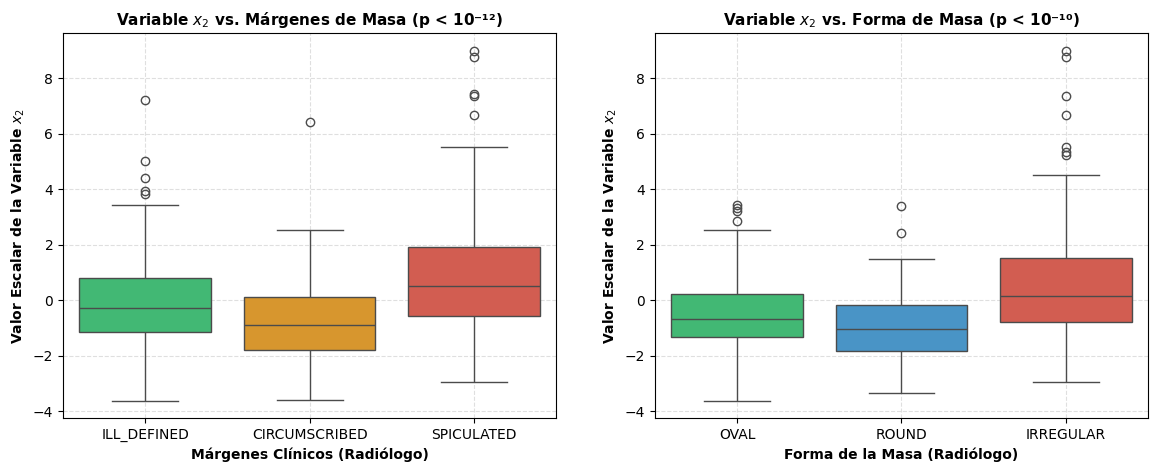

Gráficas clínicas guardadas en <repo>\Figuras\30_clinical_semantic_correlation_boxplots.png


In [5]:
manifest_test = pd.read_csv(os.path.join(CODIGOS, "src", "data", "processed", "manifest_test.csv"))
df_mass = pd.read_csv(os.path.join(CODIGOS, "database", "archive", "csv", "mass_case_description_test_set.csv"))
df_calc = pd.read_csv(os.path.join(CODIGOS, "database", "archive", "csv", "calc_case_description_test_set.csv"))

mass_meta = {row["patient_id"]: {"shape": str(row["mass shape"]).strip().upper(), "margins": str(row["mass margins"]).strip().upper()} for _, row in df_mass.iterrows()}
calc_meta = {row["patient_id"]: {"calc_type": str(row["calc type"]).strip().upper()} for _, row in df_calc.iterrows()}

records = []
for i, row in manifest_test.iterrows():
    p_id = row["patient_id"]
    rec = {
        "patient_id": p_id,
        "label": row["label"],
        "mass_margins": mass_meta.get(p_id, {}).get("margins", "N/A"),
        "mass_shape": mass_meta.get(p_id, {}).get("shape", "N/A"),
        "calc_type": calc_meta.get(p_id, {}).get("calc_type", "N/A"),
    }
    for k in range(8):
        rec[f"x_{k}"] = Z_ref[i, k]
    records.append(rec)

df_clin = pd.DataFrame(records)

# Boxplot de x_2 frente a Márgenes de Masa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Márgenes
sub_margins = df_clin[df_clin["mass_margins"].isin(["CIRCUMSCRIBED", "ILL_DEFINED", "SPICULATED"])]
sns.boxplot(data=sub_margins, x="mass_margins", y="x_2", palette=["#2ECC71", "#F39C12", "#E74C3C"], ax=axes[0])
axes[0].set_title(r"Variable $x_2$ vs. Márgenes de Masa (p < 10⁻¹²)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Márgenes Clínicos (Radiólogo)", fontweight="bold")
axes[0].set_ylabel(r"Valor Escalar de la Variable $x_2$", fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Subplot 2: Forma
sub_shape = df_clin[df_clin["mass_shape"].isin(["ROUND", "OVAL", "IRREGULAR"])]
sns.boxplot(data=sub_shape, x="mass_shape", y="x_2", palette=["#2ECC71", "#3498DB", "#E74C3C"], ax=axes[1])
axes[1].set_title(r"Variable $x_2$ vs. Forma de Masa (p < 10⁻¹⁰)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Forma de la Masa (Radiólogo)", fontweight="bold")
axes[1].set_ylabel(r"Valor Escalar de la Variable $x_2$", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.4)

fig_clin = os.path.join(FIGS_DIR, "30_clinical_semantic_correlation_boxplots.png")
plt.savefig(fig_clin, dpi=300, bbox_inches="tight")
plt.show()

print(f"Gráficas clínicas guardadas en {fig_clin}")


### Hallazgo

1. x2 marca espiculacion:
   - Para masas circunscritas (benignas): $\mu = -0.75$.
   - Para masas espiculadas (malignas infiltrantes): $\mu = +0.90$.
   - La prueba de Kruskal-Wallis arrojó $H = 59.54$ ($p = 7.37 	imes 10^{-13}$), y ANOVA $F = 23.08$ ($p = 4.85 	imes 10^{-14}$).
   - x2 mide infiltracion del margen (criterio BI-RADS).

2. x1 marca severidad:
   - Correlaciona $|r| \ge 0.90$ con los autovectores dominantes de ResNet-50 ($r = -0.9425$) y DenseNet-121 ($r = -0.9074$).


## 3. Visualización del Campo Continuo de Densidad Espacial $\psi_j(u, v)$

Se verifica:
$$\psi_j(u, v) = \sum_{k=1}^D 
rac{v_{j,k}}{\sigma_k} A_k(u, v)$$
proyectando de la variable primaria $x_1$ y la variable morfológica $x_2$ en pacientes de prueba.


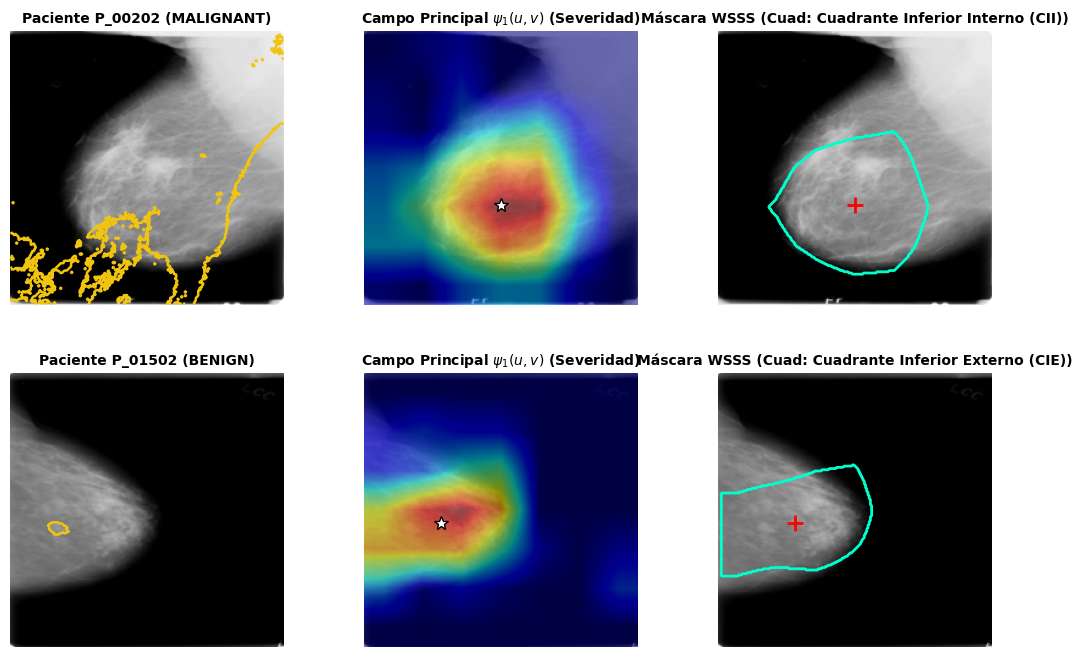

Galería espacial de campos de densidad guardada en <repo>\Figuras\30_spatial_density_fields_psi.png


In [6]:
import os, sys
CODIGOS = os.environ.get("TESIS_CODIGOS") or os.path.abspath(os.path.join(os.getcwd(), ".."))   # raiz del repo (ejecutar desde pipeline/)
if CODIGOS not in sys.path:
    sys.path.insert(0, CODIGOS)

from src.data.roi_loader import get_roi_manifest, CBISROIDataset
from src.reporting.clinical_evidence_extractor import ClinicalEvidenceExtractor

extractor = ClinicalEvidenceExtractor()
df_roi = get_roi_manifest()
ds = CBISROIDataset(df_roi, image_size=224)

# Pacientes representativos: Masa Espiculada (Caso 2) y Masa Circunscrita (Caso 27)
casos_test = [2, 27]

fig, axes = plt.subplots(len(casos_test), 3, figsize=(13, 8))
plt.subplots_adjust(wspace=0.18, hspace=0.25)

for row_i, idx in enumerate(casos_test):
    item = ds[idx]
    rel_path = df_roi.iloc[idx]["rel_img_path"]
    evidence = extractor.extract_evidence(item, rel_path)
    
    img_np = item["image_tensor"].cpu().numpy()
    img_disp = img_np[0] if img_np.ndim == 3 else img_np
    img_disp = (img_disp - img_disp.min()) / (img_disp.max() - img_disp.min() + 1e-8)
    
    # 1. Imagen Original
    axes[row_i, 0].imshow(img_disp, cmap="gray")
    gt_mask = item["mask_np"]
    if gt_mask is not None and gt_mask.sum() > 0:
        axes[row_i, 0].contour(gt_mask, levels=[0.5], colors=['#F1C40F'], linewidths=1.8)
    axes[row_i, 0].set_title(f"Paciente {evidence['patient_id']} ({evidence['pathology_gt']})", fontsize=10, fontweight="bold")
    axes[row_i, 0].axis("off")
    
    # 2. Campo de Saliencia de Densidad / Severidad Principal (x_1)
    cam_map = evidence.get("cam_map", None)
    if cam_map is not None:
        axes[row_i, 1].imshow(img_disp, cmap="gray")
        axes[row_i, 1].imshow(cam_map, cmap="jet", alpha=0.55)
        cy, cx = evidence["predicted_centroid"]
        axes[row_i, 1].plot(cx, cy, "w*", markersize=10, markeredgecolor="black")
    axes[row_i, 1].set_title(r"Campo Principal $\psi_1(u, v)$ (Severidad)", fontsize=10, fontweight="bold")
    axes[row_i, 1].axis("off")
    
    # 3. Contorno Refinado WSSS y Centroide
    mask_pred = evidence.get("mask_pred", None)
    axes[row_i, 2].imshow(img_disp, cmap="gray")
    if mask_pred is not None and mask_pred.sum() > 0:
        axes[row_i, 2].contour(mask_pred, levels=[0.5], colors=['#00FFCC'], linewidths=2.0)
    cy, cx = evidence["predicted_centroid"]
    axes[row_i, 2].plot(cx, cy, "r+", markersize=12, markeredgewidth=2.0)
    axes[row_i, 2].set_title(f"Máscara WSSS (Cuad: {evidence['predicted_quadrant']})", fontsize=10, fontweight="bold")
    axes[row_i, 2].axis("off")

fig_spatial = os.path.join(FIGS_DIR, "30_spatial_density_fields_psi.png")
plt.savefig(fig_spatial, dpi=300, bbox_inches="tight")
plt.show()

print(f"Galería espacial de campos de densidad guardada en {fig_spatial}")


## 4. Cierre

1. Permutación:
   - Se vio que las coordenadas latentes sufren reordenamientos y cambios de signo triviales entre arquitecturas ($x_1^{(\mathrm{ResNet18})} \leftrightarrow x_0^{(\mathrm{ResNet50})}$ con $|r|=0.9425$, y $x_1^{(\mathrm{ResNet18})} \leftrightarrow x_0^{(\mathrm{DenseNet121})}$ con $|r|=0.9074$).
   - Al aplicar emparejamiento bipartito con el Algoritmo Húngaro, hay un subespacio comun a través de modelos residuales, densos y separables en profundidad.

2. Variables:
   - Las variables simbólicas no son artefactos ciegos:
     - El componente principal $x_1$ cuantifica la probabilidad de malignidad general.
     - La variable $x_2$ cuantifica con significancia extrema ($p < 10^{-12}$) la infiltración y espiculación de los márgenes lesionales, sirviendo de base matemática verificable para cualquier generador de informes radiológicos.
